4001 instantes, 21 colisiones leidas
Grafica guardada en trayectorias.png


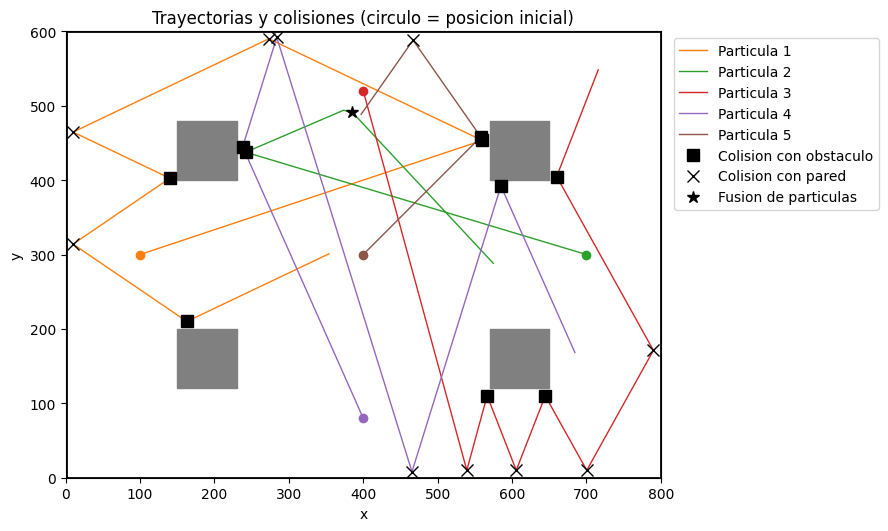

In [4]:
"""
Lee el archivo de salida de la simulacion (salida.txt) y lo grafica.

Uso:
    python graficar.py                      -> trayectorias (guarda trayectorias.png)
    python graficar.py salida.txt           -> idem, con otro archivo
    python graficar.py --animar             -> animacion en ventana
    python graficar.py --animar --gif a.gif -> guarda la animacion como GIF
    python graficar.py --animar --salto 5   -> usa 1 de cada 5 pasos (mas fluido/lento)

En Colab/Jupyter: sube salida.txt y ejecuta  %run graficar.py --animar --salto 20
Requiere: pip install matplotlib   (y pillow si quieres GIF)
Formato de lineas: CAJA,w,h | OBST,x,y,lado | POS,t,id,x,y,r | COL,t,tipo,idA,idB
"""
import argparse
import sys
from collections import defaultdict

import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Circle, Rectangle

ESTILO_COL = {            # tipo -> (marcador, etiqueta)
    "pared":     ("x", "Colision con pared"),
    "obstaculo": ("s", "Colision con obstaculo"),
    "fusion":    ("*", "Fusion de particulas"),
}


def en_notebook():
    """True si se ejecuta en Jupyter / Google Colab."""
    return "ipykernel" in sys.modules or "google.colab" in sys.modules


def leer(ruta):
    caja, obst = None, []
    tiempos = []                       # tiempos en orden (texto, para usarlo de llave)
    pos = defaultdict(dict)            # t -> {id: (x, y, r)}
    cols = []                          # (t, tipo, idA, idB)
    with open(ruta) as f:
        for linea in f:
            c = linea.strip().split(",")
            if c[0] == "CAJA":
                caja = (float(c[1]), float(c[2]))
            elif c[0] == "OBST":
                obst.append((float(c[1]), float(c[2]), float(c[3])))
            elif c[0] == "POS":
                t = c[1]
                if not tiempos or tiempos[-1] != t:
                    tiempos.append(t)
                pos[t][int(c[2])] = (float(c[3]), float(c[4]), float(c[5]))
            elif c[0] == "COL":
                cols.append((c[1], c[2], int(c[3]), int(c[4])))
    return caja, obst, tiempos, pos, cols


def posicion_colision(t, idA, pos):
    return pos[t][idA][:2] if idA in pos.get(t, {}) else None


def dibujar_escenario(ax, caja, obst):
    ax.set_xlim(0, caja[0]); ax.set_ylim(0, caja[1])
    ax.set_aspect("equal")
    ax.add_patch(Rectangle((0, 0), caja[0], caja[1], fill=False, lw=2))
    for x, y, l in obst:
        ax.add_patch(Rectangle((x, y), l, l, color="0.5"))
    ax.set_xlabel("x"); ax.set_ylabel("y")


def color(i):
    return plt.cm.tab10(i % 10)


def grafica_trayectorias(caja, obst, tiempos, pos, cols, salida="trayectorias.png"):
    fig, ax = plt.subplots(figsize=(9, 7))
    dibujar_escenario(ax, caja, obst)

    tray = defaultdict(lambda: ([], []))
    for t in tiempos:
        for i, (x, y, _) in pos[t].items():
            tray[i][0].append(x); tray[i][1].append(y)
    for i, (xs, ys) in tray.items():
        ax.plot(xs, ys, lw=1, color=color(i), label=f"Particula {i}")
        ax.plot(xs[0], ys[0], "o", color=color(i))         # inicio

    usados = set()
    for t, tipo, a, b in cols:
        p = posicion_colision(t, a, pos)
        if p is None:
            continue
        marca, etiqueta = ESTILO_COL[tipo]
        ax.plot(*p, marca, color="k", ms=9,
                label=None if tipo in usados else etiqueta)
        usados.add(tipo)

    ax.set_title("Trayectorias y colisiones (circulo = posicion inicial)")
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
    fig.tight_layout()
    fig.savefig(salida, dpi=150)
    print(f"Grafica guardada en {salida}")


def animar(caja, obst, tiempos, pos, cols, salto, gif):
    fig, ax = plt.subplots(figsize=(8, 6.5))
    dibujar_escenario(ax, caja, obst)

    ids = sorted({i for t in tiempos for i in pos[t]})
    circulos = {i: Circle((0, 0), 1, color=color(i)) for i in ids}
    for c in circulos.values():
        c.set_visible(False); ax.add_patch(c)
    texto = ax.text(0.01, 1.01, "", transform=ax.transAxes)
    puntos, = ax.plot([], [], "k*", ms=9)       # colisiones ya ocurridas

    col_por_t = defaultdict(list)
    for t, tipo, a, b in cols:
        p = posicion_colision(t, a, pos)
        if p:
            col_por_t[t].append(p)
    vistos = {"x": [], "y": []}

    cuadros = tiempos[::salto]

    def actualizar(k):
        t = cuadros[k]
        for i, c in circulos.items():
            if i in pos[t]:
                x, y, r = pos[t][i]
                c.center = (x, y); c.set_radius(r); c.set_visible(True)
            else:
                c.set_visible(False)
        # incluye las colisiones de los pasos saltados
        ini = tiempos.index(cuadros[k - 1]) + 1 if k else 0
        for tt in tiempos[ini:tiempos.index(t) + 1]:
            for x, y in col_por_t.get(tt, []):
                vistos["x"].append(x); vistos["y"].append(y)
        puntos.set_data(vistos["x"], vistos["y"])
        texto.set_text(f"t = {float(t):.2f} s")
        return list(circulos.values()) + [puntos, texto]

    anim = FuncAnimation(fig, actualizar, frames=len(cuadros), interval=30, blit=False)
    if gif:
        anim.save(gif, writer="pillow", fps=30)
        print(f"Animacion guardada en {gif}")
    elif en_notebook():
        from IPython.display import HTML, display
        plt.close(fig)                       # evita mostrar el cuadro estatico
        display(HTML(anim.to_jshtml()))      # reproductor dentro del notebook
    else:
        plt.show()


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("archivo", nargs="?", default="salida.txt")
    ap.add_argument("--animar", action="store_true")
    ap.add_argument("--gif", help="guardar la animacion en este GIF")
    ap.add_argument("--salto", type=int, default=10, help="1 de cada N pasos")
    argv = sys.argv[1:]
    if "-f" in argv:                  # Colab/Jupyter agregan "-f <kernel.json>"
        i = argv.index("-f")
        del argv[i:i + 2]
    a = ap.parse_args(argv)

    caja, obst, tiempos, pos, cols = leer(a.archivo)
    print(f"{len(tiempos)} instantes, {len(cols)} colisiones leidas")
    if a.animar:
        animar(caja, obst, tiempos, pos, cols, a.salto, a.gif)
    else:
        grafica_trayectorias(caja, obst, tiempos, pos, cols)
        plt.show()